# NFL Fourth-Down Decision Analysis

**Research Question:** When should NFL teams go for it on fourth down instead of punting or attempting a field goal?

**Author:** Ben Peterson

**Data:** NFL play-by-play data, 2021–2025

**Project Goals:**
1. Explore fourth-down decisions and conversion rates.
2. Build models to predict fourth-down conversion probability.
3. Compare decisions using expected points.
4. Communicate findings through visualizations and a professional report.



In [ ]:
import pandas as pd

url = "https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_2025.parquet"

pbp = pd.read_parquet(url)

print("rows:", pbp.shape[0])
print("columns:", pbp.shape[1])

pbp.head()


rows: 48771
columns: 372


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2025_01_ARI_NO,2025090705,NO,ARI,REG,1,None,None,None,...,0.0,0.0,-0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,40.0,2025_01_ARI_NO,2025090705,NO,ARI,REG,1,ARI,away,NO,...,0.0,0.0,-0.352700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,63.0,2025_01_ARI_NO,2025090705,NO,ARI,REG,1,ARI,away,NO,...,0.0,0.0,-0.190052,NaN,NaN,NaN,NaN,NaN,0.511128,-51.112807
3,85.0,2025_01_ARI_NO,2025090705,NO,ARI,REG,1,ARI,away,NO,...,1.0,0.0,1.317340,0.939998,4.750889,3.0,0.666726,0.43911,0.668940,33.105969
4,115.0,2025_01_ARI_NO,2025090705,NO,ARI,REG,1,ARI,away,NO,...,0.0,0.0,-1.694360,NaN,NaN,NaN,NaN,NaN,0.492038,50.796208


In [ ]:
columns = [
    'season', 'week', 'posteam', 'down',
    'ydstogo', 'yardline_100', 'play_type',
    'fourth_down_converted', 'epa', 'wp'
]

pbp[columns].head(10)


,season,week,posteam,down,ydstogo,yardline_100,play_type,fourth_down_converted,epa,wp
0,2025,1,None,NaN,0.0,NaN,None,NaN,-0.000000,0.433208
1,2025,1,ARI,NaN,0.0,35.0,kickoff,0.0,-0.352700,0.433208
2,2025,1,ARI,1.0,10.0,78.0,run,0.0,-0.190052,0.433909
3,2025,1,ARI,2.0,7.0,75.0,pass,0.0,1.317340,0.419904
4,2025,1,ARI,1.0,10.0,64.0,pass,0.0,-1.694360,0.454899
5,2025,1,ARI,2.0,21.0,75.0,run,0.0,-1.284150,0.404215
6,2025,1,ARI,3.0,23.0,77.0,run,0.0,-0.840574,0.379757
7,2025,1,ARI,4.0,22.0,76.0,punt,0.0,0.650589,0.343042
8,2025,1,NO,1.0,10.0,77.0,run,0.0,-0.194728,0.613374
9,2025,1,NO,2.0,7.0,74.0,pass,0.0,-0.788527,0.602262


In [ ]:
fourth_down = pbp[pbp['down'] == 4].copy()

print("total fourth-down records:", len(fourth_down))

print("\nplay types:")
print(fourth_down['play_type'].value_counts(dropna=False))

fourth_down[columns].head(10)


total fourth-down records: 4290

play types:
play_type
punt          2042
field_goal    1024
pass           596
run            335
no_play        289
qb_kneel         4
Name: count, dtype: int64


,season,week,posteam,down,ydstogo,yardline_100,play_type,fourth_down_converted,epa,wp
7,2025,1,ARI,4.0,22.0,76.0,punt,0.0,0.650589,0.343042
11,2025,1,NO,4.0,7.0,74.0,punt,0.0,-0.436324,0.549005
25,2025,1,ARI,4.0,12.0,24.0,field_goal,0.0,0.859787,0.468741
64,2025,1,NO,4.0,5.0,18.0,field_goal,0.0,0.345913,0.543092
88,2025,1,NO,4.0,13.0,69.0,punt,0.0,0.349710,0.229736
94,2025,1,ARI,4.0,12.0,32.0,field_goal,0.0,1.341322,0.738212
111,2025,1,NO,4.0,5.0,20.0,field_goal,0.0,-3.622557,0.211396
117,2025,1,ARI,4.0,11.0,61.0,punt,0.0,-0.767115,0.830232
125,2025,1,NO,4.0,7.0,60.0,punt,0.0,0.605227,0.117600
136,2025,1,ARI,4.0,9.0,59.0,punt,0.0,-0.297218,0.918532


In [ ]:
import numpy as np

valid_plays = ['run', 'pass', 'punt', 'field_goal']

fourth_clean = fourth_down[
    fourth_down['play_type'].isin(valid_plays)
].copy()

fourth_clean['decision'] = np.select(
    [
        fourth_clean['play_type'].isin(['run', 'pass']),
        fourth_clean['play_type'] == 'punt',
        fourth_clean['play_type'] == 'field_goal'
    ],
    ['Go for it', 'Punt', 'Field goal'],
    default='Other'
)

print("total classified fourth downs:", len(fourth_clean))

print("\ndecision counts:")
print(fourth_clean['decision'].value_counts())

print("\ndecision percentages:")
print((fourth_clean['decision'].value_counts(normalize=True) * 100).round(2))


total classified fourth downs: 3997

decision counts:
decision
Punt          2042
Field goal    1024
Go for it      931
Name: count, dtype: int64

decision percentages:
decision
Punt          51.09
Field goal    25.62
Go for it     23.29
Name: proportion, dtype: float64


decision        Field goal  Go for it   Punt
distance_group                              
1                     3.65      76.88  19.47
2-3                  20.72      39.14  40.13
4-5                  34.38      21.71  43.91
6-10                 32.72       9.60  57.68
11+                  24.85       5.78  69.37


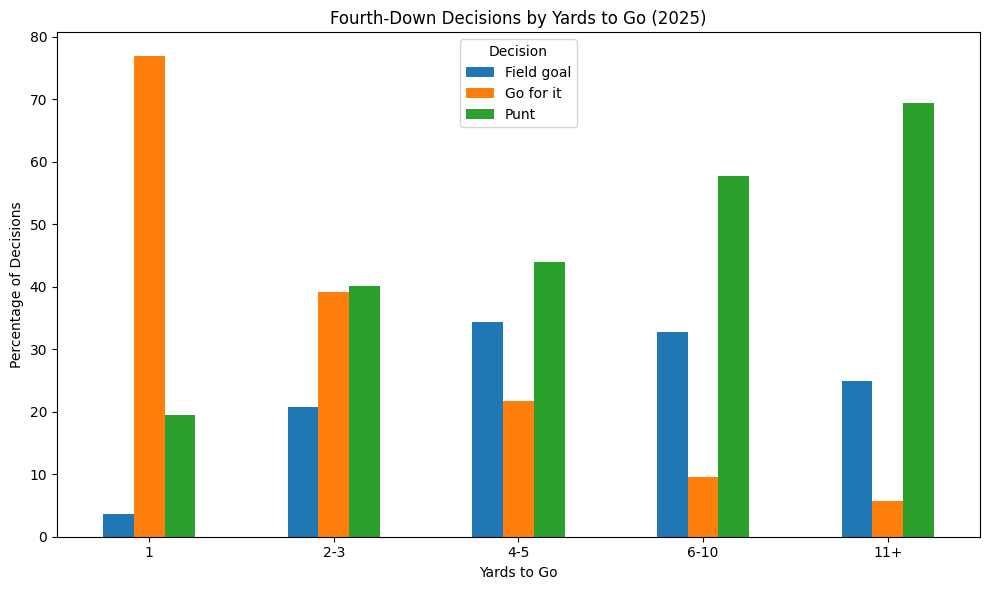

In [ ]:
import matplotlib.pyplot as plt

distance_data = fourth_clean[
    fourth_clean['ydstogo'].notna() &
    (fourth_clean['ydstogo'] > 0)
].copy()

distance_data['distance_group'] = pd.cut(
    distance_data['ydstogo'],
    bins=[0, 1, 3, 5, 10, float('inf')],
    labels=['1', '2-3', '4-5', '6-10', '11+']
)

decision_table = pd.crosstab(
    distance_data['distance_group'],
    distance_data['decision'],
    normalize='index'
) * 100

print(decision_table.round(2))

decision_table.plot(kind='bar', figsize=(10, 6))

plt.title('Fourth-Down Decisions by Yards to Go (2025)')
plt.xlabel('Yards to Go')
plt.ylabel('Percentage of Decisions')
plt.xticks(rotation=0)
plt.legend(title='Decision')
plt.tight_layout()
plt.show()


decision        Field goal  Go for it   Punt
field_position                              
Opponent 1-20        64.61      35.39   0.00
Opponent 21-40       65.80      30.37   3.83
Midfield area         1.90      29.10  69.00
Own 21-40             0.00       9.92  90.08
Own 1-20              0.00       3.82  96.18


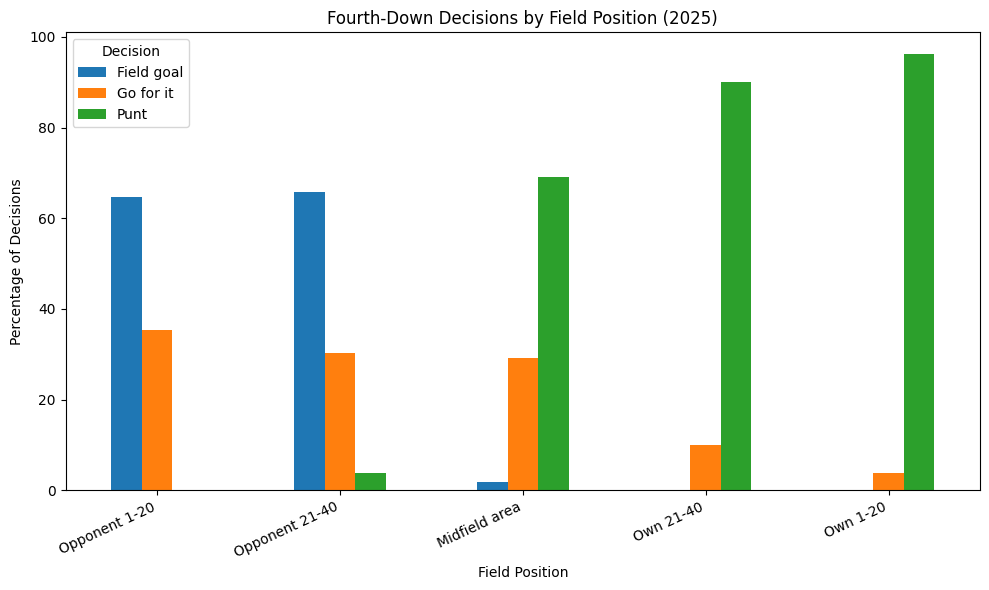

In [ ]:
field_data = fourth_clean[
    fourth_clean['yardline_100'].between(1, 99)
].copy()

field_data['field_position'] = pd.cut(
    field_data['yardline_100'],
    bins=[0, 20, 40, 60, 80, 100],
    labels=[
        'Opponent 1-20',
        'Opponent 21-40',
        'Midfield area',
        'Own 21-40',
        'Own 1-20'
    ]
)

field_table = pd.crosstab(
    field_data['field_position'],
    field_data['decision'],
    normalize='index'
) * 100

print(field_table.round(2))

field_table.plot(kind='bar', figsize=(10, 6))

plt.title('Fourth-Down Decisions by Field Position (2025)')
plt.xlabel('Field Position')
plt.ylabel('Percentage of Decisions')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Decision')
plt.tight_layout()
plt.show()


In [ ]:
excluded = fourth_down[
    ~fourth_down['play_type'].isin(['run', 'pass', 'punt', 'field_goal'])
].copy()

print("excluded play types:")
print(excluded['play_type'].value_counts(dropna=False))

print("\nmissing values in important columns:")
important_columns = [
    'ydstogo', 'yardline_100', 'play_type',
    'fourth_down_converted', 'epa'
]

print(fourth_clean[important_columns].isna().sum())

print("\nexamples of excluded plays:")
print(excluded[['play_type', 'desc']].head(15).to_string(index=False))

excluded play types:
play_type
no_play     289
qb_kneel      4
Name: count, dtype: int64

missing values in important columns:
ydstogo                  0
yardline_100             0
play_type                0
fourth_down_converted    0
epa                      0
dtype: int64

examples of excluded plays:
play_type                                                                                                                                                                                                                                                                    desc
  no_play                                                                                      (2:46) 19-B.Grupe 23 yard field goal is GOOD, NULLIFIED by Penalty, Center-49-Z.Wood, Holder-32-K.Kroeger. PENALTY on NO, Illegal Formation, 5 yards, enforced at ARI 5 - No Play.
  no_play                                                                                               (8:42) (Shotgun) 17-J.Allen pass incomplete 

In [ ]:
seasons = [2021, 2022, 2023, 2024, 2025]

all_seasons = []

for season in seasons:
    url = f"https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_{season}.parquet"
    season_data = pd.read_parquet(url)

    all_seasons.append(season_data)

    print(season, ":", len(season_data), "plays")

pbp_all = pd.concat(all_seasons, ignore_index=True)

print("\ntotal plays:", len(pbp_all))
print("total columns:", len(pbp_all.columns))

print("\nplays by season:")
print(pbp_all['season'].value_counts().sort_index())

2021 : 49922 plays
2022 : 49434 plays
2023 : 49665 plays
2024 : 49492 plays
2025 : 48771 plays

total plays: 247284
total columns: 372

plays by season:
season
2021    49922
2022    49434
2023    49665
2024    49492
2025    48771
Name: count, dtype: int64


In [ ]:
fourth_all = pbp_all[pbp_all['down'] == 4].copy()

valid_plays = ['run', 'pass', 'punt', 'field_goal']

fourth_all_clean = fourth_all[
    fourth_all['play_type'].isin(valid_plays)
].copy()

fourth_all_clean['decision'] = np.select(
    [
        fourth_all_clean['play_type'].isin(['run', 'pass']),
        fourth_all_clean['play_type'] == 'punt',
        fourth_all_clean['play_type'] == 'field_goal'
    ],
    ['Go for it', 'Punt', 'Field goal'],
    default='Other'
)

print("total fourth-down records:", len(fourth_all))
print("classified fourth-down records:", len(fourth_all_clean))

print("\ndecisions by season:")
print(pd.crosstab(
    fourth_all_clean['season'],
    fourth_all_clean['decision']
))

print("\nmissing values:")
print(fourth_all_clean[
    ['ydstogo', 'yardline_100', 'fourth_down_converted', 'epa']
].isna().sum())

total fourth-down records: 21613
classified fourth-down records: 20269

decisions by season:
decision  Field goal  Go for it  Punt
season                               
2021             969        826  2187
2022            1007        770  2294
2023            1037        833  2352
2024            1063        815  2119
2025            1024        931  2042

missing values:
ydstogo                  0
yardline_100             0
fourth_down_converted    0
epa                      0
dtype: int64


In [ ]:
# check missing values across all columns
missing = fourth_all_clean.isna().sum()
missing_percent = fourth_all_clean.isna().mean() * 100

missing_summary = pd.DataFrame({
    'missing_count': missing,
    'missing_percent': missing_percent.round(2)
})

print("top 20 columns with missing values:")
print(
    missing_summary[missing_summary['missing_count'] > 0]
    .sort_values('missing_percent', ascending=False)
    .head(20)
)

# check variables relevant to our analysis
important_columns = [
    'season', 'week', 'posteam', 'defteam',
    'down', 'ydstogo', 'yardline_100',
    'score_differential', 'game_seconds_remaining',
    'qtr', 'play_type', 'fourth_down_converted', 'epa'
]

print("\nmissing values in important variables:")
print(missing_summary.loc[important_columns])

top 20 columns with missing values:
                                    missing_count  missing_percent
extra_point_result                          20269            100.0
two_point_conv_result                       20269            100.0
assist_tackle_3_player_name                 20269            100.0
tackle_for_loss_2_player_id                 20269            100.0
tackle_for_loss_2_player_name               20269            100.0
st_play_type                                20269            100.0
end_yard_line                               20269            100.0
tackle_with_assist_2_player_name            20269            100.0
assist_tackle_4_player_id                   20269            100.0
assist_tackle_4_player_name                 20269            100.0
assist_tackle_4_team                        20269            100.0
assist_tackle_3_team                        20269            100.0
tackle_with_assist_2_team                   20269            100.0
forced_fumble_player_2_pla

In [ ]:
important_columns = [
    'season', 'week', 'posteam', 'defteam',
    'down', 'ydstogo', 'yardline_100',
    'score_differential', 'game_seconds_remaining',
    'qtr', 'play_type', 'fourth_down_converted', 'epa'
]

missing_summary = pd.DataFrame({
    'missing_count': fourth_all_clean.isna().sum(),
    'missing_percent': (
        fourth_all_clean.isna().mean() * 100
    ).round(2)
})

print("missing values in important variables:")
print(missing_summary.loc[important_columns])

print("\ntop 15 columns with missing values:")
print(
    missing_summary[missing_summary['missing_count'] > 0]
    .sort_values('missing_percent', ascending=False)
    .head(15)
)

missing values in important variables:
                        missing_count  missing_percent
season                              0              0.0
week                                0              0.0
posteam                             0              0.0
defteam                             0              0.0
down                                0              0.0
ydstogo                             0              0.0
yardline_100                        0              0.0
score_differential                  0              0.0
game_seconds_remaining              0              0.0
qtr                                 0              0.0
play_type                           0              0.0
fourth_down_converted               0              0.0
epa                                 0              0.0

top 15 columns with missing values:
                                    missing_count  missing_percent
extra_point_result                          20269            100.0
two_point_conv_resul